In [1]:
import matplotlib as mpl
import pandas as pd

from matplotlib import pyplot as plt

In [2]:
table = pd.read_csv("table-raw.csv")

In [3]:
tab20c = mpl.colormaps["tab20c"].colors

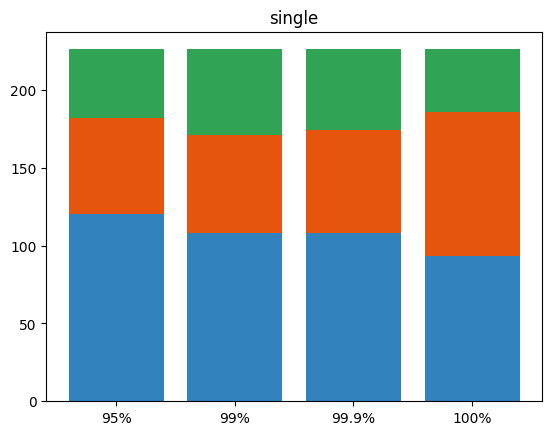

In [4]:
fig, ax = plt.subplots()

percentiles = ["95%", "99%", "99.9%", "100%"]
kinds = ["absolute", "relative", "quadratic"]
colours = [tab20c[0], tab20c[4], tab20c[8]]

for i, percentile in enumerate(percentiles):
    base = 0

    for kind, c in zip(kinds, colours):
        count = len(
            table[
                (table["level"] == "single")
                & (table["percentile"] == percentile)
                & (table["pick"] == kind)
            ]
        )

        ax.bar(i, count, bottom=base, color=c)

        base += count

ax.set_title("single")
ax.set_xticks(range(len(percentiles)))
ax.set_xticklabels(percentiles)

plt.show()

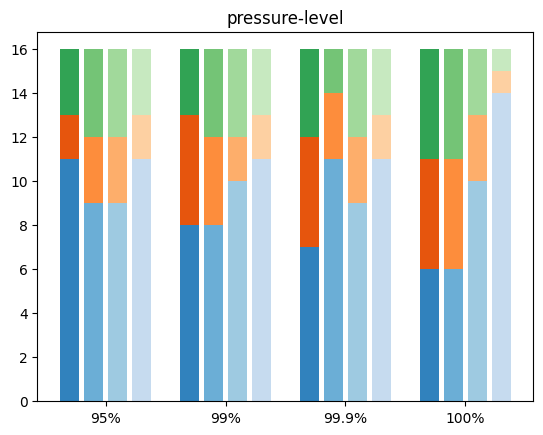

In [5]:
fig, ax = plt.subplots()

percentiles = ["95%", "99%", "99.9%", "100%"]
levels = ["1000.0 hPa", "850.0 hPa", "500.0 hPa", "50.0 hPa"]
kinds = ["absolute", "relative", "quadratic"]

for i, percentile in enumerate(percentiles):
    for j, level in enumerate(levels):
        colours = [tab20c[0 + j], tab20c[4 + j], tab20c[8 + j]]

        base = 0

        for kind, c in zip(kinds, colours):
            count = len(
                table[
                    (table["level"] == level)
                    & (table["percentile"] == percentile)
                    & (table["pick"] == kind)
                ]
            )

            ax.bar(i * (len(levels) + 1) + j, count, bottom=base, color=c)

            base += count

ax.set_title("pressure-level")
ax.set_xticks([i * 5 + 1.5 for i in range(len(percentiles))])
ax.set_xticklabels(percentiles)

plt.show()